In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)

TensorFlow Version: 2.21.0
NumPy Version: 2.5.5


In [2]:
# Load MNIST Dataset

(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Display dataset information

print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 12s 1us/step
Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)


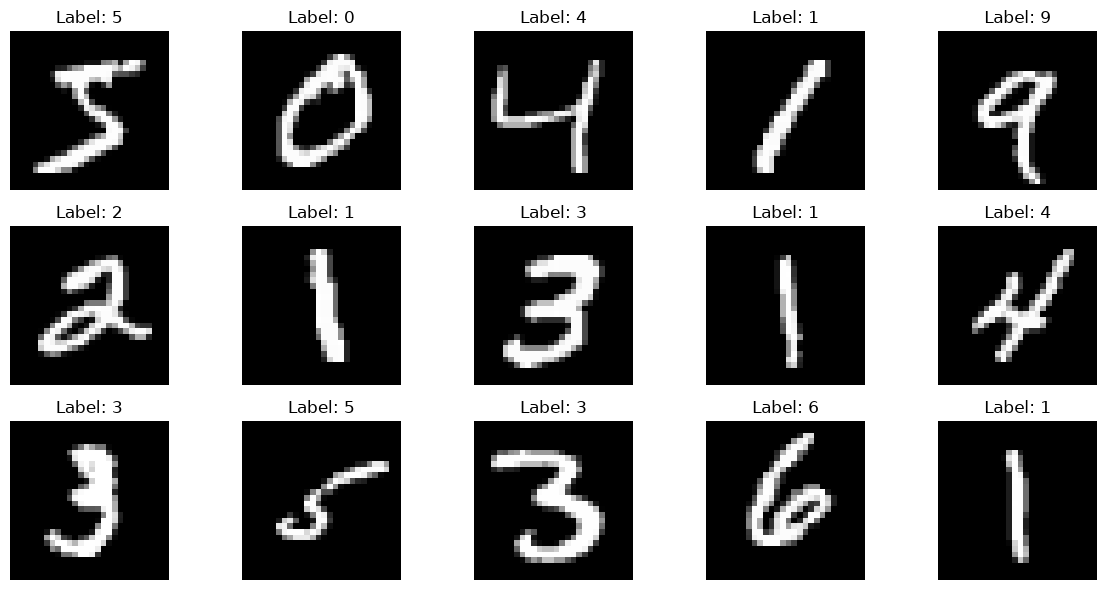

In [3]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
print("========== DATASET INFORMATION ==========")

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("Image Height:", X_train.shape[1])
print("Image Width:", X_train.shape[2])

print("Number of Classes:", len(np.unique(y_train)))

print("Unique Labels:", np.unique(y_train))

print("Data Type:", X_train.dtype)

print("Minimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())

========== DATASET INFORMATION ==========
Training Samples: 60000
Testing Samples: 10000
Image Height: 28
Image Width: 28
Number of Classes: 10
Unique Labels: [0 1 2 3 4 5 6 7 8 9]
Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 255


   Digit  Number of Images
0      0              5923
1      1              6742
2      2              5958
3      3              6131
4      4              5842
5      5              5421
6      6              5918
7      7              6265
8      8              5851
9      9              5949


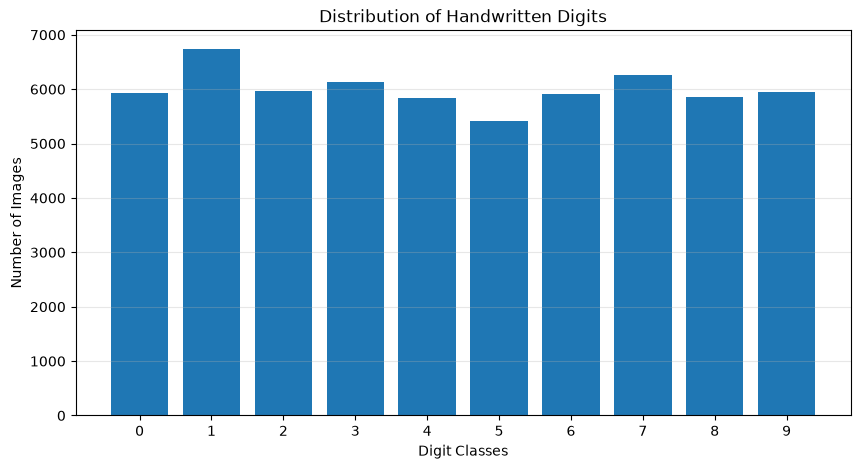

In [5]:
import pandas as pd

unique, counts = np.unique(y_train, return_counts=True)

class_distribution = pd.DataFrame({
    "Digit": unique,
    "Number of Images": counts
})

print(class_distribution)

plt.figure(figsize=(10, 5))

plt.bar(unique, counts)

plt.title("Distribution of Handwritten Digits")
plt.xlabel("Digit Classes")
plt.ylabel("Number of Images")

plt.xticks(range(10))
plt.grid(axis="y", alpha=0.3)

plt.show()

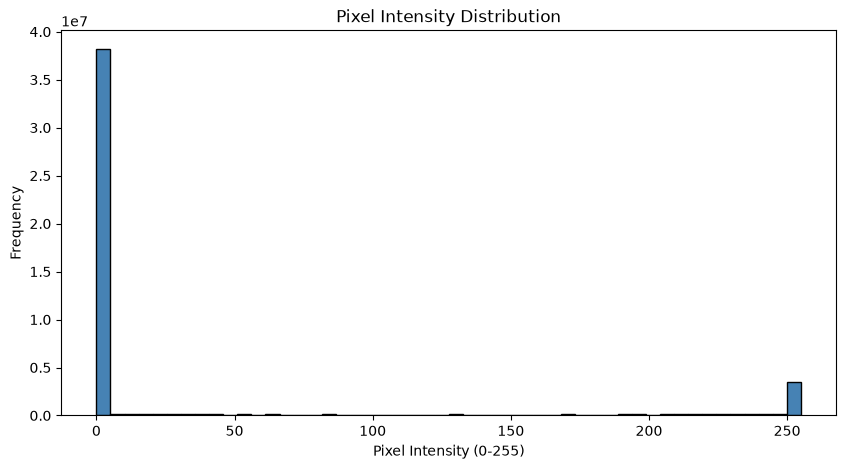

In [6]:
plt.figure(figsize=(10, 5))

plt.hist(
    X_train.flatten(),
    bins=50,
    color="steelblue",
    edgecolor="black"
)

plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity (0-255)")
plt.ylabel("Frequency")

plt.show()

Digit Label: 5
Image Shape: (28, 28)

Pixel Matrix:

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0  

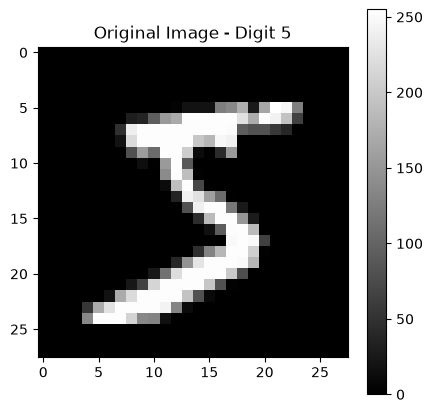

In [7]:
sample_image = X_train[0]

print("Digit Label:", y_train[0])
print("Image Shape:", sample_image.shape)

print("\nPixel Matrix:\n")
print(sample_image)

plt.figure(figsize=(5, 5))

plt.imshow(sample_image, cmap="gray")
plt.title(f"Original Image - Digit {y_train[0]}")
plt.colorbar()

plt.show()

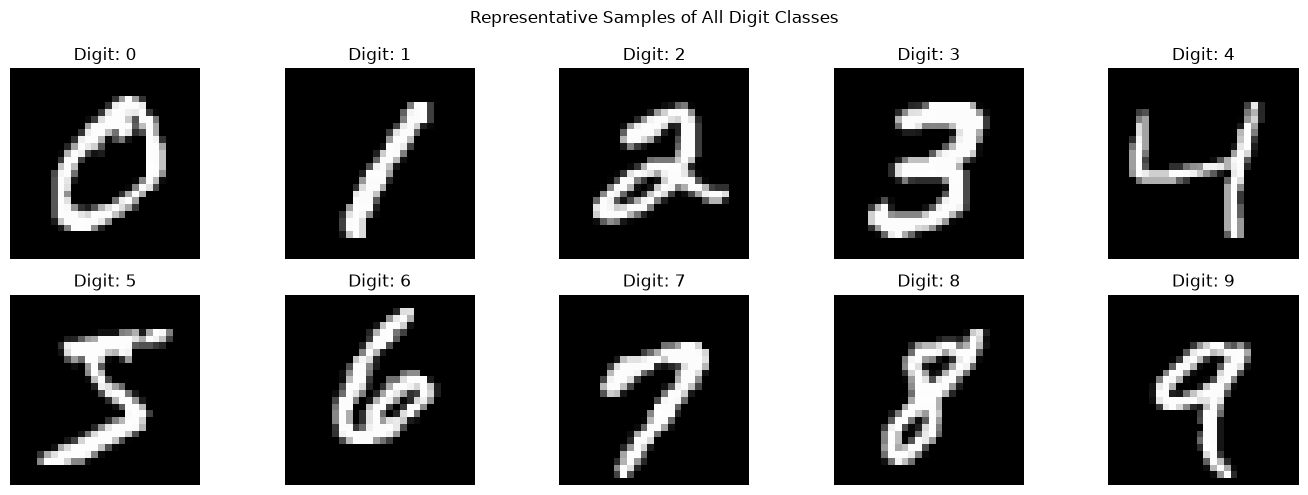

In [8]:
plt.figure(figsize=(14, 5))

for digit in range(10):

    index = np.where(y_train == digit)[0][0]

    plt.subplot(2, 5, digit + 1)

    plt.imshow(X_train[index], cmap="gray")
    plt.title(f"Digit: {digit}")

    plt.axis("off")

plt.suptitle("Representative Samples of All Digit Classes")

plt.tight_layout()
plt.show()

## 3. Data Preprocessing

In [9]:
# Normalize pixel values

X_train_normalized = X_train.astype("float32") / 255.0
X_test_normalized = X_test.astype("float32") / 255.0

print("Training Data Range:")
print("Minimum:", X_train_normalized.min())
print("Maximum:", X_train_normalized.max())

print("\nTesting Data Range:")
print("Minimum:", X_test_normalized.min())
print("Maximum:", X_test_normalized.max())

Training Data Range:
Minimum: 0.0
Maximum: 1.0

Testing Data Range:
Minimum: 0.0
Maximum: 1.0


In [10]:
# Reshape images for CNN

X_train_processed = X_train_normalized.reshape(
    -1, 28, 28, 1
)

X_test_processed = X_test_normalized.reshape(
    -1, 28, 28, 1
)

print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Training Shape: (60000, 28, 28, 1)
Testing Shape: (10000, 28, 28, 1)


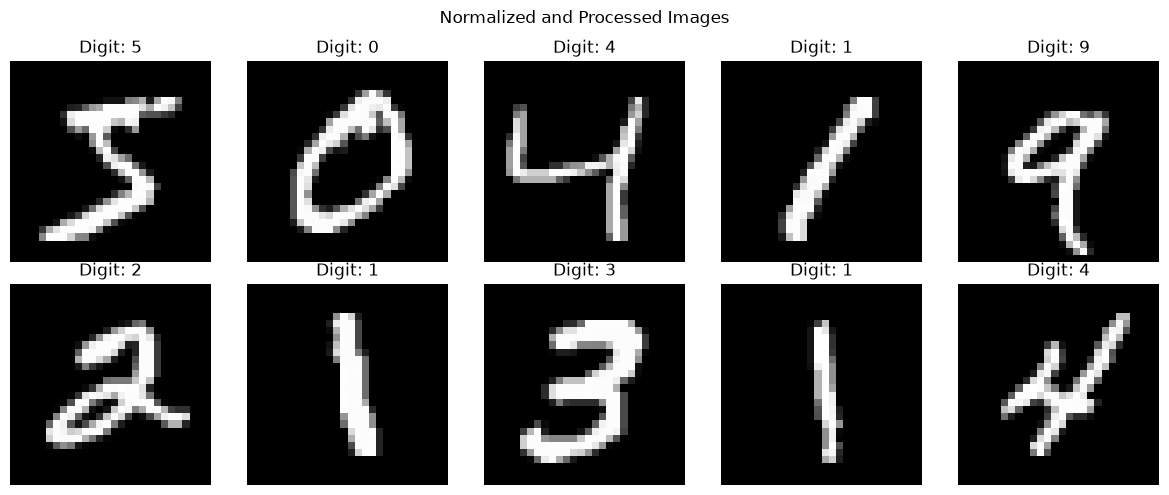

In [11]:
plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_train_processed[i].squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Normalized and Processed Images")

plt.tight_layout()
plt.show()

In [12]:
# Data Augmentation Pipeline

data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomRotation(0.04),

    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),

    tf.keras.layers.RandomZoom(0.05)

], name="data_augmentation")

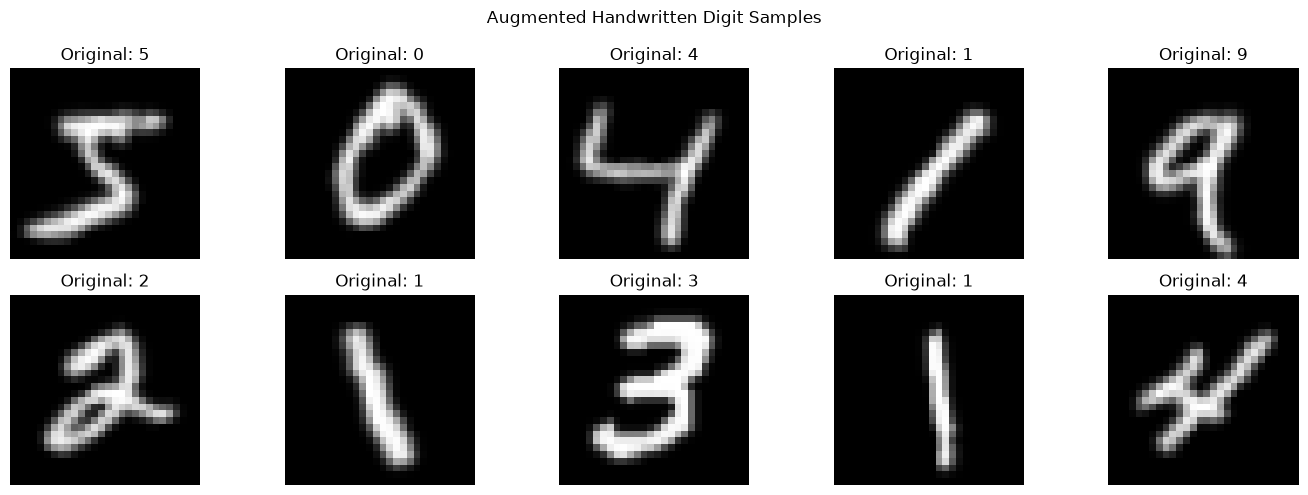

In [13]:
# Select sample images

sample_images = X_train_processed[:10]

# Apply augmentation

augmented_images = data_augmentation(
    sample_images,
    training=True
)

plt.figure(figsize=(14, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        augmented_images[i].numpy().squeeze(),
        cmap="gray"
    )

    plt.title(f"Original: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Augmented Handwritten Digit Samples")

plt.tight_layout()
plt.show()

In [14]:
print("========== PREPROCESSING SUMMARY ==========")

print("Training Samples:", X_train_processed.shape[0])
print("Testing Samples:", X_test_processed.shape[0])

print("Image Dimensions:", X_train_processed.shape[1:])

print("Training Data Type:", X_train_processed.dtype)

print("Pixel Minimum:", X_train_processed.min())
print("Pixel Maximum:", X_train_processed.max())

print("Number of Classes:", len(np.unique(y_train)))

print("\nPreprocessing Completed Successfully!")

========== PREPROCESSING SUMMARY ==========
Training Samples: 60000
Testing Samples: 10000
Image Dimensions: (28, 28, 1)
Training Data Type: float32
Pixel Minimum: 0.0
Pixel Maximum: 1.0
Number of Classes: 10

Preprocessing Completed Successfully!


## 4. CNN Model Architecture

In [15]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Activation,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

# Build CNN Model

model = Sequential([

    Input(shape=(28, 28, 1)),

    # Convolution Block 1
    Conv2D(32, (3, 3), padding="same", use_bias=False),
    BatchNormalization(),
    Activation("relu"),
    MaxPooling2D((2, 2)),

    # Convolution Block 2
    Conv2D(64, (3, 3), padding="same", use_bias=False),
    BatchNormalization(),
    Activation("relu"),
    MaxPooling2D((2, 2)),

    # Convolution Block 3
    Conv2D(128, (3, 3), padding="same", use_bias=False),
    BatchNormalization(),
    Activation("relu"),

    # Feature Extraction
    GlobalAveragePooling2D(),

    # Classification
    Dense(128, activation="relu"),
    Dropout(0.4),

    # Output
    Dense(10, activation="softmax")

], name="Handwritten_Digit_CNN")

In [16]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


In [17]:
model.summary()

Model: "Handwritten_Digit_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,146 (434.16 KB)

 Trainable params: 110,698 (432.41 KB)

 Non-trainable params: 448 (1.75 KB)

## 5. Model Training

In [18]:
from sklearn.model_selection import train_test_split

# Split training data into training and validation sets

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

print("Training Samples:", X_train_final.shape[0])
print("Validation Samples:", X_val.shape[0])
print("Testing Samples:", X_test_processed.shape[0])

Training Samples: 54000
Validation Samples: 6000
Testing Samples: 10000


In [19]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(28, 28, 1)),

    # Data Augmentation
    data_augmentation,

    # Convolution Block 1
    tf.keras.layers.Conv2D(
        32, (3, 3), padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    tf.keras.layers.Conv2D(
        64, (3, 3), padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    tf.keras.layers.Conv2D(
        128, (3, 3), padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),

    # Feature Extraction
    tf.keras.layers.GlobalAveragePooling2D(),

    # Classification
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.4),

    # Output
    tf.keras.layers.Dense(10, activation="softmax")

], name="Handwritten_Digit_CNN")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "Handwritten_Digit_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,146 (434.16 KB)

 Trainable params: 110,698 (432.41 KB)

 Non-trainable params: 448 (1.75 KB)

In [20]:
callbacks = [

    # Save best performing model
    tf.keras.callbacks.ModelCheckpoint(
        "best_digit_cnn.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    # Stop training if validation stops improving
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    # Reduce learning rate when progress slows
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    )
]

In [21]:
history = model.fit(

    X_train_final,
    y_train_final,

    validation_data=(X_val, y_val),

    epochs=25,
    batch_size=128,

    callbacks=callbacks,

    verbose=1
)

Epoch 1/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.8688 - loss: 0.4541
Epoch 1: val_accuracy improved from None to 0.11700, saving model to best_digit_cnn.keras

Epoch 1: finished saving model to best_digit_cnn.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 50s 111ms/step - accuracy: 0.8688 - loss: 0.4541 - val_accuracy: 0.1170 - val_loss: 8.7527 - learning_rate: 0.0010
Epoch 2/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.9677 - loss: 0.1129
Epoch 2: val_accuracy improved from 0.11700 to 0.93550, saving model to best_digit_cnn.keras

Epoch 2: finished saving model to best_digit_cnn.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 111ms/step - accuracy: 0.9677 - loss: 0.1129 - val_accuracy: 0.9355 - val_loss: 0.2170 - learning_rate: 0.0010
Epoch 3/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.9742 - loss: 0.0864
Epoch 3: val_accuracy did not improve from 0.93550
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 100ms/step - accuracy: 0.9742 - loss: 0.0864 - val_accuracy: 0.8988 - 

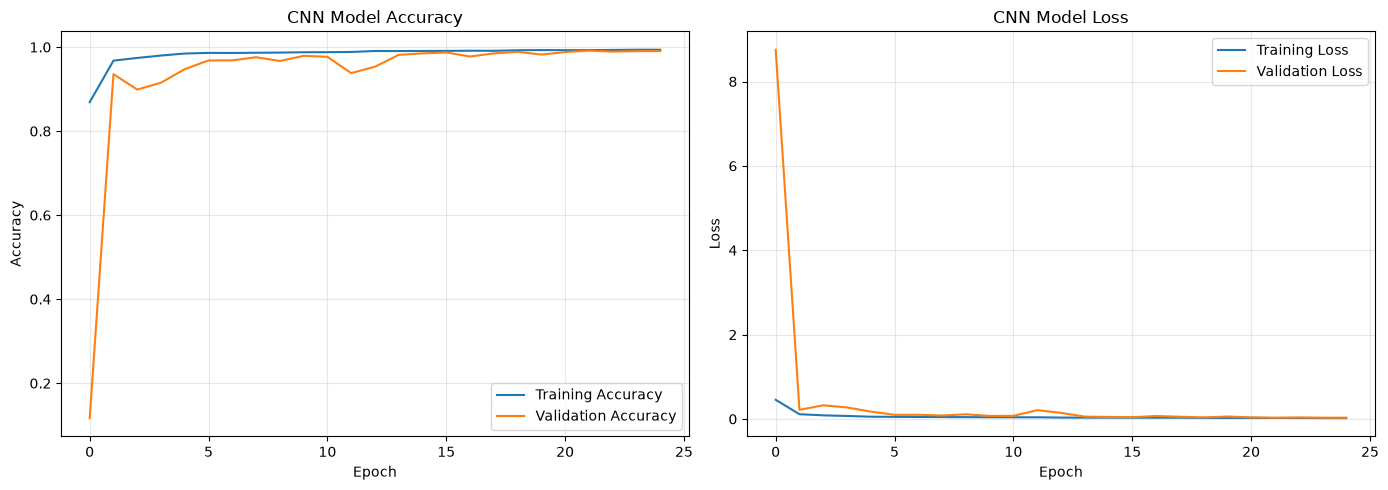

In [22]:
plt.figure(figsize=(14, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)

# Loss Plot
plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Model Evaluation

In [23]:
# Evaluate CNN on unseen test data

test_loss, test_accuracy = model.evaluate(
    X_test_processed,
    y_test,
    verbose=1
)

print("\n========== FINAL TEST RESULTS ==========")

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9908 - loss: 0.0273

========== FINAL TEST RESULTS ==========
Test Accuracy: 99.08%
Test Loss: 0.0273


In [24]:
# Predict probabilities for all test images

y_pred_prob = model.predict(
    X_test_processed,
    verbose=1
)

# Convert probabilities into predicted digit classes

y_pred = np.argmax(y_pred_prob, axis=1)

print("Actual Labels:", y_test[:20])
print("Predicted Labels:", y_pred[:20])

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
Actual Labels: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]
Predicted Labels: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


In [25]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    labels=list(range(10)),
    target_names=[str(i) for i in range(10)],
    digits=4
)

print("========== CLASSIFICATION REPORT ==========")
print(report)

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0     0.9939    0.9939    0.9939       980
           1     0.9878    0.9956    0.9917      1135
           2     0.9932    0.9893    0.9913      1032
           3     0.9911    0.9941    0.9926      1010
           4     0.9790    0.9990    0.9889       982
           5     0.9944    0.9922    0.9933       892
           6     0.9968    0.9833    0.9900       958
           7     0.9855    0.9903    0.9879      1028
           8     0.9918    0.9908    0.9913       974
           9     0.9960    0.9792    0.9875      1009

    accuracy                         0.9908     10000
   macro avg     0.9909    0.9908    0.9908     10000
weighted avg     0.9908    0.9908    0.9908     10000



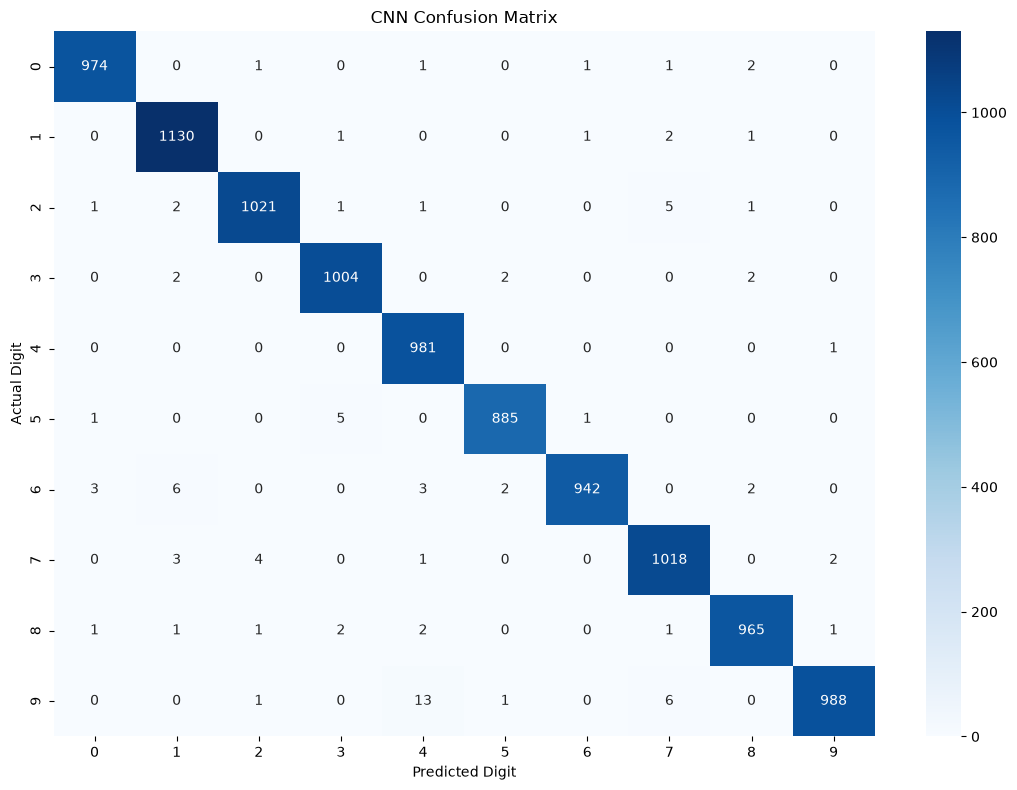

In [26]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")

plt.tight_layout()
plt.show()

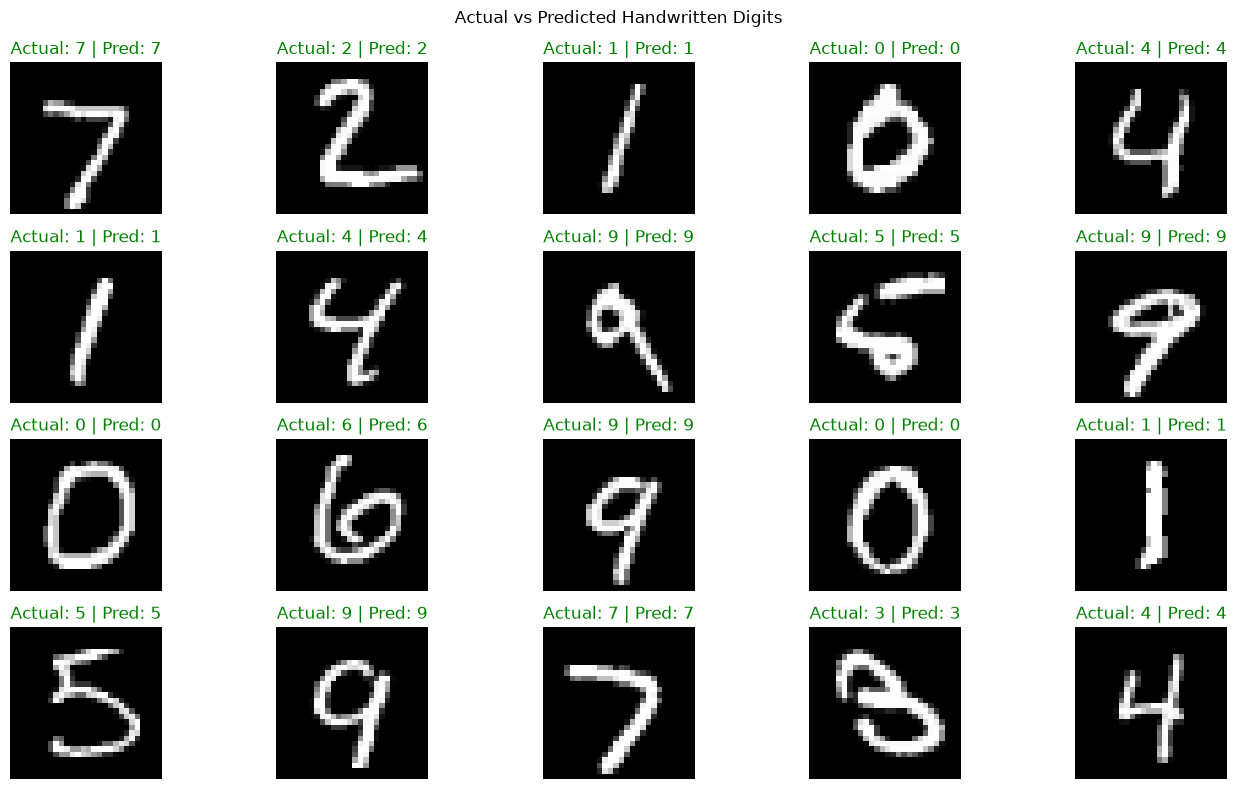

In [27]:
plt.figure(figsize=(14, 8))

for i in range(20):

    plt.subplot(4, 5, i + 1)

    plt.imshow(
        X_test_processed[i].squeeze(),
        cmap="gray"
    )

    actual = y_test[i]
    predicted = y_pred[i]

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {actual} | Pred: {predicted}",
        color=color
    )

    plt.axis("off")

plt.suptitle("Actual vs Predicted Handwritten Digits")

plt.tight_layout()
plt.show()

In [28]:
# Save the trained CNN model

model.save("../models/final_digit_recognition.keras")

print("Final CNN Model Saved Successfully!")

Final CNN Model Saved Successfully!
